# Decoding cursor velocity, and losing it 274 days later

A linear decoder maps threshold-crossing rates onto the cursor's velocity, which is the regression the paper uses as its Static baseline. Within a session it works. The point of this dataset is what happens when the same decoder meets the other session, recorded 274 days later on the same two arrays: that collapse is the problem NoMAD exists to solve, and it is what this release is uniquely good for.

Everything here is a plain ridge regression on smoothed rates, with no alignment, no recalibration and no attempt to hide the gap.

In [1]:
import matplotlib.pyplot as plt
import neuralset as ns
import numpy as np
from scipy.ndimage import gaussian_filter1d

from neuralshed.datasets.utils import dataset_dir
from neuralshed.datasets.karpowicz_2025.study import Karpowicz2025CursorStability
from neuralshed.extractors import BehavioralSeriesExtractor, NeuralFeatureExtractor

FS = 50.0
SMOOTH_MS = 100.0     # Gaussian kernel on the rates, as the paper smooths before decoding
WINDOW_S = 0.6        # the span the paper defines intent over
RIDGE = 1e2

## The data

All 20 blocks, both sessions. One segment per movement, the first 600 ms of it, giving the neural input and the velocity to predict.

In [2]:
study = Karpowicz2025CursorStability(path=str(dataset_dir("karpowicz_2025") / "data"))
events = study.run()

segmenter = ns.dataloader.Segmenter(
    extractors={
        "neural": NeuralFeatureExtractor(target_unit="Hz", frequency=FS, event_types="SpikeCounts"),
        "velocity": BehavioralSeriesExtractor(frequency=FS, event_types="DecodedCursorVelocitySeries"),
    },
    trigger_query="type == 'Action'",
    duration=WINDOW_S,
)
segments = segmenter.apply(events)
segments.prepare()

batch = segments.load_all()
neural = np.asarray(batch.data["neural"], dtype=np.float64)
velocity = np.asarray(batch.data["velocity"], dtype=np.float64)
triggers = batch.triggers

print(f"movements: {len(neural)}  neural {neural.shape}  velocity {velocity.shape}")
print(triggers.groupby(["session", "task"]).size().to_string())

2026-08-25 19:34:55 - INFO - neuralset.dataloader:222 - Preparing extractor: NeuralFeatureExtractor


  0%|          | 0/20 [00:00<?, ?it/s]

 70%|███████   | 14/20 [00:00<00:00, 136.00it/s]

100%|██████████| 20/20 [00:00<00:00, 132.51it/s]


2026-08-25 19:34:55 - INFO - neuralset.dataloader:222 - Preparing extractor: BehavioralSeriesExtractor


  0%|          | 0/20 [00:00<?, ?it/s]

100%|██████████| 20/20 [00:00<00:00, 4541.26it/s]

movements: 1112  neural (1112, 192, 30)  velocity (1112, 2, 30)
session     task                
T11_day153  centeroutcalibration     33
            simonsequence           611
T11_day427  centeroutcalibration     47
            simonsequence           421


## Per-bin samples

Each 600 ms movement becomes 30 samples, one per bin: 192 smoothed rates in, an (x, y) velocity out. The paper uses a single bin of history for T11, so no lags are stacked here.

In [3]:
smoothed = gaussian_filter1d(neural, sigma=SMOOTH_MS / 1000 * FS, axis=2)

n_movements, n_channels, n_bins = smoothed.shape
features = smoothed.transpose(0, 2, 1).reshape(-1, n_channels)
targets = velocity.transpose(0, 2, 1).reshape(-1, 2)

# Carry each sample's block and session so splits stay at the block level.
session = np.repeat(triggers["session"].to_numpy(), n_bins)
block = np.repeat(triggers["block"].to_numpy().astype(int), n_bins)
calibration = np.repeat(triggers["task"].to_numpy() == "centeroutcalibration", n_bins)

finite = np.isfinite(features).all(axis=1) & np.isfinite(targets).all(axis=1)
features, targets = features[finite], targets[finite]
session, block, calibration = session[finite], block[finite], calibration[finite]

print(f"samples: {len(features)} of {len(finite)} kept")
print(f"velocity range: {targets.min():.2f} to {targets.max():.2f} a.u./s")

samples: 33360 of 33360 kept
velocity range: -1.43 to 1.62 a.u./s


In [4]:
def fit(x, y, ridge=RIDGE):
    """Ridge regression with an intercept, standardized inputs. Returns a predict function."""
    mean, scale = x.mean(axis=0), x.std(axis=0) + 1e-6
    z = (x - mean) / scale
    z = np.c_[z, np.ones(len(z))]
    penalty = ridge * np.eye(z.shape[1])
    penalty[-1, -1] = 0.0
    weights = np.linalg.solve(z.T @ z + penalty, z.T @ y)
    return lambda new: np.c_[(new - mean) / scale, np.ones(len(new))] @ weights


def r2(y, prediction):
    """Fraction of variance explained, pooled over both axes, in the original units."""
    return 1 - ((y - prediction) ** 2).sum() / ((y - y.mean(axis=0)) ** 2).sum()

## Within a session

Train on the Simon blocks of day 153 and hold out its last two, which is an ordinary within-session split.

In [5]:
day153_simon = (session == "T11_day153") & ~calibration
blocks_153 = np.unique(block[day153_simon])
held_out = blocks_153[-2:]

train = day153_simon & ~np.isin(block, held_out)
test = day153_simon & np.isin(block, held_out)

decoder = fit(features[train], targets[train])
within = r2(targets[test], decoder(features[test]))

print(f"train blocks {blocks_153[:-2].tolist()} -> test blocks {held_out.tolist()}")
print(f"within-session R2: {within:.2f}")

train blocks [5, 6, 7, 8, 9, 10, 11, 12] -> test blocks [13, 14]
within-session R2: 0.64


## The same decoder, 274 days later

No retraining, no alignment: the day 153 decoder simply reads day 427's arrays.

In [6]:
day427_simon = (session == "T11_day427") & ~calibration
across = r2(targets[day427_simon], decoder(features[day427_simon]))

# What a supervised recalibration would buy: refit on day 427's own calibration block.
day427_calibration = (session == "T11_day427") & calibration
recalibrated = fit(features[day427_calibration], targets[day427_calibration])
after_recalibration = r2(targets[day427_simon], recalibrated(features[day427_simon]))

# And the ceiling: train on day 427's own Simon blocks, hold out its last two.
blocks_427 = np.unique(block[day427_simon])
within_427 = r2(
    targets[day427_simon & np.isin(block, blocks_427[-2:])],
    fit(
        features[day427_simon & ~np.isin(block, blocks_427[-2:])],
        targets[day427_simon & ~np.isin(block, blocks_427[-2:])],
    )(features[day427_simon & np.isin(block, blocks_427[-2:])]),
)

print(f"day 153 decoder on day 153 (held out) : R2 {within:.2f}")
print(f"day 153 decoder on day 427            : R2 {across:.2f}")
print(f"day 427 calibration block, refit      : R2 {after_recalibration:.2f}")
print(f"day 427 trained on its own blocks     : R2 {within_427:.2f}")

day 153 decoder on day 153 (held out) : R2 0.64
day 153 decoder on day 427            : R2 -0.30
day 427 calibration block, refit      : R2 -0.03
day 427 trained on its own blocks     : R2 0.47


The transfer number is the honest one, and it is worse than useless: a decoder that explains 0.64 of the variance on its own day scores **below zero** 274 days later, meaning the day 153 weights predict day 427's cursor worse than that session's mean velocity does. Refitting on day 427's own calibration block barely helps either, because that block is a different task at a different cursor gain. Only training on day 427's own Simon blocks recovers a working decoder.

### Is it just a gain change?

The two sessions ran different Kalman filters, so the cursor moves at different speeds, and a scale mismatch alone would sink R2 while leaving the shape of the prediction intact. It is worth separating the two, because rescaling is cheap and re-learning a population is not.

In [7]:
prediction = decoder(features[day427_simon])
actual = targets[day427_simon]

print(f"99th percentile speed: day 153 {np.percentile(np.abs(targets[day153_simon]), 99):.2f}, day 427 {np.percentile(np.abs(actual), 99):.2f} a.u./s")
for axis, name in enumerate("xy"):
    correlation = np.corrcoef(actual[:, axis], prediction[:, axis])[0, 1]
    print(f"  {name} axis: correlation {correlation:+.2f}")

# An oracle rescale: refit gain and offset per axis on day 427 itself, which is the most
# a scale correction could ever buy.
rescaled = np.stack(
    [np.polyval(np.polyfit(prediction[:, axis], actual[:, axis], 1), prediction[:, axis]) for axis in range(2)],
    axis=1,
)
print(f"R2 after an oracle per-axis rescale: {r2(actual, rescaled):.2f}")

99th percentile speed: day 153 0.65, day 427 1.03 a.u./s
  x axis: correlation -0.10
  y axis: correlation +0.34
R2 after an oracle per-axis rescale: 0.05


So no. The y axis keeps a weak positive correlation, the x axis is gone entirely, and even an oracle rescale fitted on the test session itself only reaches R2 0.05. What changed is which channels carry which direction, which is what manifold alignment addresses and a gain correction cannot.

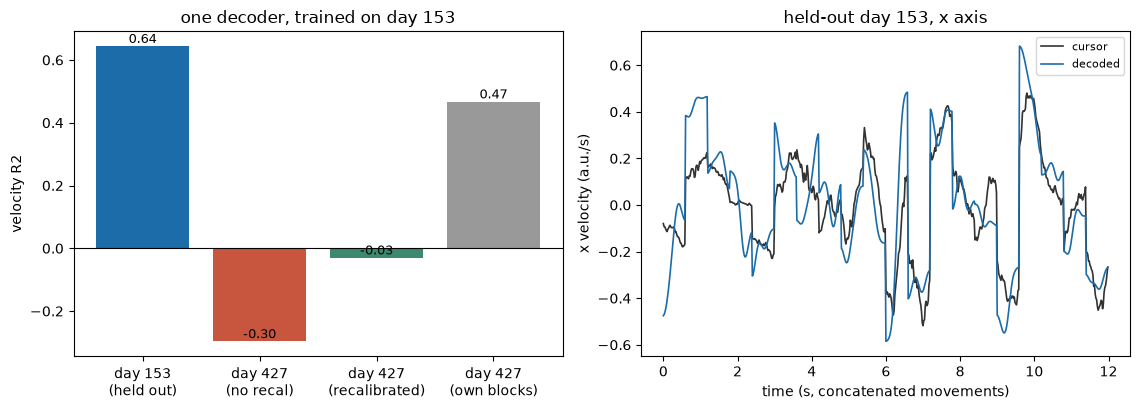

In [8]:
figure, axes = plt.subplots(1, 2, figsize=(11.5, 4.2))

labels = ["day 153\n(held out)", "day 427\n(no recal)", "day 427\n(recalibrated)", "day 427\n(own blocks)"]
scores = [within, across, after_recalibration, within_427]
colors = ["#1b6ca8", "#c8553d", "#3c896d", "#999999"]

axes[0].bar(labels, scores, color=colors)
axes[0].axhline(0, color="black", linewidth=0.8)
axes[0].set(ylabel="velocity R2", title="one decoder, trained on day 153")
for index, score in enumerate(scores):
    axes[0].text(index, score + 0.01, f"{score:.2f}", ha="center", fontsize=9)

# A stretch of held-out day 153 velocity against its prediction, x axis only.
sample = np.flatnonzero(test)[:600]
axes[1].plot(np.arange(len(sample)) / FS, targets[sample, 0], color="#333333", linewidth=1.2, label="cursor")
axes[1].plot(np.arange(len(sample)) / FS, decoder(features[sample])[:, 0], color="#1b6ca8", linewidth=1.2, label="decoded")
axes[1].set(xlabel="time (s, concatenated movements)", ylabel="x velocity (a.u./s)", title="held-out day 153, x axis")
axes[1].legend(fontsize=8)

figure.tight_layout()

## Where the ceiling is

The levers left on the table are the paper's own subject matter, not model capacity:

- **Representation, not architecture.** Smoothed rates are a weak input; the paper's gains come from LFADS generator states, which lift its within-session fit from R2 0.47 to 0.86 before any alignment is attempted.
- **Alignment.** Nothing here maps day 427's population onto day 153's latent space, which is the whole of NoMAD, and the section above shows why nothing cheaper will do.
- **Two sessions is a small stability benchmark.** The monkey deposit from the same paper spans many more days and is the better place to measure a decay curve.
- **Labels are not free.** The one thing that worked was training on day 427's own Simon blocks, which means labelled data from the session you want to decode. Removing that requirement is the point of the unsupervised methods.